# Inteligência Artificial – XMCO01 – Atividade de Aprendizado de Máquina

## Introdução

Neste trabalho, usamos MLP e Random Forest para classificar notícias por popularidade e K-Means para identificar grupos de notícias com características semelhantes. Para cada modelo, comparamos os resultados nas versões original e modificada do conjunto de dados.

**Conjunto de dados** · [Online News Popularity](https://archive.ics.uci.edu/dataset/332/online+news+popularity)

### Carregamento dos dados

In [1]:
import time
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    silhouette_samples,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("OnlineNewsPopularity.csv")

df.columns = df.columns.str.strip()

df.head()

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


## Preparação dos dados

Criamos duas versões do dataset para comparar os resultados dos modelos:

- **Original:** mantém os atributos do dataset.
- **Modificado:** remove `url`, `timedelta` e as colunas de `kw_min_min` até `kw_max_avg`, conforme solicitado.

In [3]:
df_original = df.copy()

keyword_columns = df.loc[:, "kw_min_min":"kw_max_avg"].columns

df_modified = df.drop(
    columns=["url", "timedelta", *keyword_columns]
)

print("Original:", df_original.shape)
print("Modified:", df_modified.shape)

Original: (39644, 61)
Modified: (39644, 51)


## Classificação (MLP e Random Forest)

Definimos a variável-alvo com base no número de compartilhamentos:

- **0:** notícia não popular, com menos de 1.400 compartilhamentos.
- **1:** notícia popular, com 1.400 compartilhamentos ou mais.

Separamos a variável-alvo dos atributos de entrada para os modelos Random Forest e MLP.

In [4]:
# Classification target
y_classification = (df_original["shares"] >= 1400).astype(int)

# Classification features
X_classification_original = df_original.drop(columns=["url", "shares"])
X_classification_modified = df_modified.drop(columns=["shares"])

### Divisão treino/teste

Utilizamos 80% dos dados para treinamento e 20% para teste, com divisão estratificada e `random_state=42`.

Os mesmos registros são utilizados nas versões original e modificada, garantindo comparações consistentes.

In [5]:
train_indices, test_indices = train_test_split(
    df_original.index,
    test_size=0.2,
    stratify=y_classification,
    random_state=42
)

X_train_original = X_classification_original.loc[train_indices]
X_test_original = X_classification_original.loc[test_indices]

X_train_modified = X_classification_modified.loc[train_indices]
X_test_modified = X_classification_modified.loc[test_indices]

y_train = y_classification.loc[train_indices]
y_test = y_classification.loc[test_indices]

## Classificação — MLP

Os experimentos usarão os conjuntos original e modificado já separados acima. A seleção será feita por F1 macro com validação cruzada estratificada em 3 divisões. A padronização será aplicada dentro de um Pipeline, e o tempo de treinamento será registrado.

In [6]:
mlp_scoring = "f1_macro"
mlp_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

mlp_fixed_params = {
    "activation": "relu",
    "solver": "adam",
    "max_iter": 300,
    "early_stopping": True,
    "random_state": 42,
}

mlp_configs = [
    {"hidden_layer_sizes": (32,), "alpha": 0.0001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (64,), "alpha": 0.001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (64, 32), "alpha": 0.01, "learning_rate_init": 0.0005},
]

### Pipelines do MLP

Cada configuração terá um Pipeline independente para os conjuntos original e modificado. Na validação cruzada, o StandardScaler será ajustado apenas na parte de treino de cada divisão; os conjuntos de teste permanecem reservados para a avaliação final.

In [7]:
mlp_datasets = {
    "original": {"X_train": X_train_original, "X_test": X_test_original},
    "modified": {"X_train": X_train_modified, "X_test": X_test_modified},
}

mlp_pipelines = {
    dataset_name: [
        Pipeline(steps=[
            ("scaler", StandardScaler()),
            ("mlp", MLPClassifier(**mlp_fixed_params, **config)),
        ])
        for config in mlp_configs
    ]
    for dataset_name in mlp_datasets
}

### Validação cruzada e seleção das configurações

Avaliamos as três configurações separadamente nos conjuntos original e modificado, usando apenas os dados de treino. A seleção utiliza o F1 macro médio em três divisões estratificadas; o desvio-padrão e o tempo total de cada validação também são registrados. Os conjuntos de teste ficam reservados para a avaliação final.

In [8]:
mlp_cv_results = []

for version, datasets in mlp_datasets.items():
    for config_idx, pipeline in enumerate(mlp_pipelines[version], start=1):
        print(f"Validando {version}: configuração {config_idx}/{len(mlp_configs)}...", flush=True)
        start_time = perf_counter()
        scores = cross_val_score(
            pipeline,
            datasets["X_train"],
            y_train,
            cv=mlp_cv,
            scoring=mlp_scoring,
            n_jobs=1,
        )
        elapsed_seconds = perf_counter() - start_time
        mlp_cv_results.append({
            "version": version,
            "config": config_idx,
            **mlp_configs[config_idx - 1],
            "f1_macro_mean": float(np.mean(scores)),
            "f1_macro_std": float(np.std(scores)),
            "elapsed_seconds": elapsed_seconds,
        })
        print(f"Concluído {version}, configuração {config_idx}: {elapsed_seconds:.1f} s", flush=True)

mlp_cv_table = pd.DataFrame(mlp_cv_results)
mlp_best_table = mlp_cv_table.loc[
    mlp_cv_table.groupby("version", sort=False)["f1_macro_mean"].idxmax()
].reset_index(drop=True)
mlp_best_indices = {
    row["version"]: int(row["config"]) - 1
    for _, row in mlp_best_table.iterrows()
}

print("Resultados da validação cruzada:")
display(mlp_cv_table)
print("Melhor configuração por versão (maior F1 macro médio):")
display(mlp_best_table)

Validando original: configuração 1/3...
Concluído original, configuração 1: 1.6 s
Validando original: configuração 2/3...
Concluído original, configuração 2: 1.6 s
Validando original: configuração 3/3...
Concluído original, configuração 3: 3.7 s
Validando modified: configuração 1/3...
Concluído modified, configuração 1: 1.8 s
Validando modified: configuração 2/3...
Concluído modified, configuração 2: 2.2 s
Validando modified: configuração 3/3...
Concluído modified, configuração 3: 3.5 s
Resultados da validação cruzada:


,version,config,hidden_layer_sizes,alpha,learning_rate_init,f1_macro_mean,f1_macro_std,elapsed_seconds
0,original,1,"(32,)",0.0001,0.0010,0.654679,0.001195,1.613974
1,original,2,"(64,)",0.0010,0.0010,0.651393,0.004154,1.575794
2,original,3,"(64, 32)",0.0100,0.0005,0.655771,0.002295,3.688324
3,modified,1,"(32,)",0.0001,0.0010,0.646241,0.003354,1.780656
4,modified,2,"(64,)",0.0010,0.0010,0.648196,0.001829,2.208932
5,modified,3,"(64, 32)",0.0100,0.0005,0.645611,0.006353,3.526329


Melhor configuração por versão (maior F1 macro médio):


,version,config,hidden_layer_sizes,alpha,learning_rate_init,f1_macro_mean,f1_macro_std,elapsed_seconds
0,original,3,"(64, 32)",0.010,0.0005,0.655771,0.002295,3.688324
1,modified,2,"(64,)",0.001,0.0010,0.648196,0.001829,2.208932


### Treinamento final e avaliação do MLP

Para cada versão, treinamos o Pipeline escolhido pela validação cruzada em todo o respectivo conjunto de treino. O conjunto de teste reservado é usado apenas para a avaliação final, com classification_report e matriz de confusão na ordem das classes 0 (Não popular) e 1 (Popular). Registramos também o tempo do treinamento final.

In [9]:
mlp_final_results = {}
class_labels = [0, 1]
class_names = ["Não popular", "Popular"]

for version, datasets in mlp_datasets.items():
    best_idx = mlp_best_indices[version]
    pipeline = mlp_pipelines[version][best_idx]

    start_time = perf_counter()
    pipeline.fit(datasets["X_train"], y_train)
    training_seconds = perf_counter() - start_time

    predictions = pipeline.predict(datasets["X_test"])
    report_text = classification_report(
        y_test, predictions, labels=class_labels, target_names=class_names, zero_division=0
    )
    report_metrics = classification_report(
        y_test, predictions, labels=class_labels, target_names=class_names,
        output_dict=True, zero_division=0
    )
    matrix = confusion_matrix(y_test, predictions, labels=class_labels)

    mlp_final_results[version] = {
        "pipeline": pipeline,
        "config_index": best_idx,
        "config": mlp_configs[best_idx],
        "predictions": predictions,
        "training_seconds": training_seconds,
        "classification_report": report_metrics,
        "confusion_matrix": matrix,
    }

    print(f"{version}: configuração {best_idx + 1}; treinamento final: {training_seconds:.2f} s")
    print(report_text)
    display(pd.DataFrame(
        matrix,
        index=[f"Real: {name}" for name in class_names],
        columns=[f"Previsto: {name}" for name in class_names],
    ))

original: configuração 3; treinamento final: 1.49 s
              precision    recall  f1-score   support

 Não popular       0.64      0.60      0.62      3698
     Popular       0.67      0.71      0.69      4231

    accuracy                           0.65      7929
   macro avg       0.65      0.65      0.65      7929
weighted avg       0.65      0.65      0.65      7929



,Previsto: Não popular,Previsto: Popular
Real: Não popular,2202,1496
Real: Popular,1242,2989


modified: configuração 2; treinamento final: 0.85 s
              precision    recall  f1-score   support

 Não popular       0.63      0.62      0.62      3698
     Popular       0.67      0.68      0.68      4231

    accuracy                           0.65      7929
   macro avg       0.65      0.65      0.65      7929
weighted avg       0.65      0.65      0.65      7929



,Previsto: Não popular,Previsto: Popular
Real: Não popular,2277,1421
Real: Popular,1345,2886


### Comparação dos resultados do MLP

As tabelas reúnem as métricas dos modelos finais e os acertos e erros das matrizes de confusão, usando somente os resultados já armazenados em `mlp_final_results`.

In [10]:
mlp_comparison_rows = []
mlp_confusion_rows = []

for version, result in mlp_final_results.items():
    report = result["classification_report"]
    matrix = result["confusion_matrix"]
    tn, fp, fn, tp = matrix.ravel()

    mlp_comparison_rows.append({
        "Versão": version,
        "Configuração": result["config_index"] + 1,
        "Camadas": str(result["config"]["hidden_layer_sizes"]),
        "Acurácia": report["accuracy"],
        "Precisão Popular": report["Popular"]["precision"],
        "Recall Popular": report["Popular"]["recall"],
        "F1 Popular": report["Popular"]["f1-score"],
        "F1 macro": report["macro avg"]["f1-score"],
        "Treinamento (s)": result["training_seconds"],
    })
    mlp_confusion_rows.append({
        "Versão": version,
        "VN (0→0)": int(tn),
        "FP (0→1)": int(fp),
        "FN (1→0)": int(fn),
        "VP (1→1)": int(tp),
        "Acertos": int(tn + tp),
        "Erros": int(fp + fn),
    })

mlp_comparison_table = pd.DataFrame(mlp_comparison_rows)
mlp_confusion_table = pd.DataFrame(mlp_confusion_rows)

print("Métricas dos melhores modelos MLP:")
display(mlp_comparison_table.round({
    "Acurácia": 3, "Precisão Popular": 3, "Recall Popular": 3,
    "F1 Popular": 3, "F1 macro": 3, "Treinamento (s)": 2,
}))
print("Matrizes de confusão: VN/VP são acertos; FP/FN são erros.")
display(mlp_confusion_table)

mlp_summary = {
    version: {
        "f1_macro": result["classification_report"]["macro avg"]["f1-score"],
        "accuracy": result["classification_report"]["accuracy"],
        "f1_popular": result["classification_report"]["Popular"]["f1-score"],
        "training_seconds": result["training_seconds"],
    }
    for version, result in mlp_final_results.items()
}
version_names = {"original": "original", "modified": "modificado"}
versions = ("original", "modified")

def higher_version(metric):
    return max(versions, key=lambda version: mlp_summary[version][metric])

macro_gap = abs(mlp_summary["original"]["f1_macro"] - mlp_summary["modified"]["f1_macro"])
accuracy_gap = abs(mlp_summary["original"]["accuracy"] - mlp_summary["modified"]["accuracy"])
popular_gap = abs(mlp_summary["original"]["f1_popular"] - mlp_summary["modified"]["f1_popular"])
time_gap = abs(mlp_summary["original"]["training_seconds"] - mlp_summary["modified"]["training_seconds"])

conclusion_parts = []
if macro_gap <= 0.01:
    general = "As duas versões tiveram desempenho geral semelhante no MLP"
    if macro_gap > 0:
        general += f", com pequena vantagem numérica do conjunto {version_names[higher_version('f1_macro')]} no F1 macro"
    conclusion_parts.append(general + ".")
else:
    conclusion_parts.append(
        f"O conjunto {version_names[higher_version('f1_macro')]} teve melhor desempenho geral no MLP pelo F1 macro."
    )

if accuracy_gap <= 0.01:
    conclusion_parts.append("A acurácia também ficou próxima.")
else:
    conclusion_parts.append(f"A acurácia foi maior no conjunto {version_names[higher_version('accuracy')]}.")

if popular_gap <= 0.01:
    popular = "O F1 da classe Popular foi semelhante nas duas versões"
    if popular_gap > 0:
        popular += f", com leve vantagem do conjunto {version_names[higher_version('f1_popular')]}"
    conclusion_parts.append(popular + ".")
else:
    conclusion_parts.append(
        f"O F1 da classe Popular foi maior no conjunto {version_names[higher_version('f1_popular')]}."
    )

longer_time = max(mlp_summary[version]["training_seconds"] for version in versions)
if time_gap >= 1.0 and time_gap / max(longer_time, 1e-9) >= 0.10:
    faster_version = min(versions, key=lambda version: mlp_summary[version]["training_seconds"])
    conclusion_parts.append(f"O treinamento final foi mais rápido no conjunto {version_names[faster_version]}.")

display(Markdown("### Conclusão parcial do MLP\n\n" + " ".join(conclusion_parts)))

Métricas dos melhores modelos MLP:


,Versão,Configuração,Camadas,Acurácia,Precisão Popular,Recall Popular,F1 Popular,F1 macro,Treinamento (s)
0,original,3,"(64, 32)",0.655,0.666,0.706,0.686,0.651,1.49
1,modified,2,"(64,)",0.651,0.670,0.682,0.676,0.649,0.85


Matrizes de confusão: VN/VP são acertos; FP/FN são erros.


,Versão,VN (0→0),FP (0→1),FN (1→0),VP (1→1),Acertos,Erros
0,original,2202,1496,1242,2989,5191,2738
1,modified,2277,1421,1345,2886,5163,2766


### Conclusão parcial do MLP

As duas versões tiveram desempenho geral semelhante no MLP, com pequena vantagem numérica do conjunto original no F1 macro. A acurácia também ficou próxima. O F1 da classe Popular foi semelhante nas duas versões, com leve vantagem do conjunto original.

## Classificação — Random Forest

Comparamos os conjuntos original e modificado usando o Random Forest.

Parâmetros testados

- **Random Forest:** `n_estimators` (número de árvores), `max_depth` (profundidade máxima), `min_samples_leaf` (mínimo de amostras por folha), `class_weight` (peso das classes), `random_state` e `n_jobs`.

O Random Forest é treinado sem padronização. A divisão de treino e teste é a mesma para os dois conjuntos.


Original - Random Forest - configuração 1
              precision    recall  f1-score   support

           0       0.65      0.58      0.62      3698
           1       0.67      0.73      0.70      4231

    accuracy                           0.66      7929
   macro avg       0.66      0.66      0.66      7929
weighted avg       0.66      0.66      0.66      7929



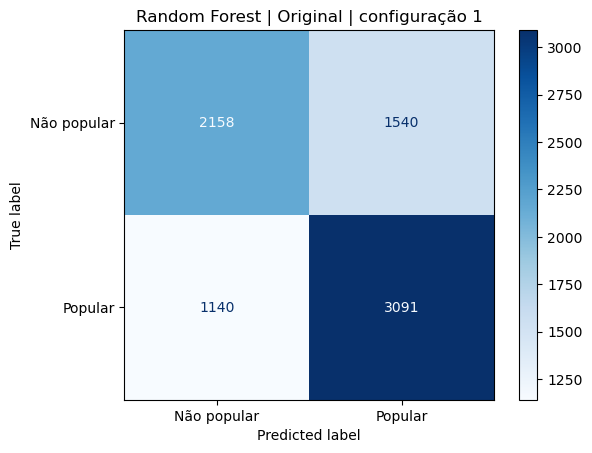


Original - Random Forest - configuração 2
              precision    recall  f1-score   support

           0       0.65      0.60      0.63      3698
           1       0.67      0.72      0.69      4231

    accuracy                           0.66      7929
   macro avg       0.66      0.66      0.66      7929
weighted avg       0.66      0.66      0.66      7929



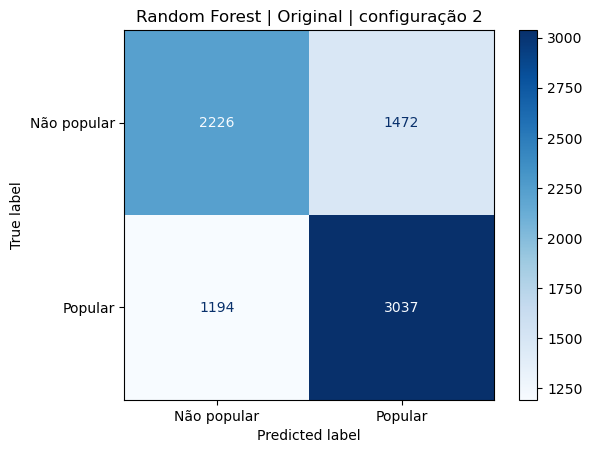


Modificado - Random Forest - configuração 1
              precision    recall  f1-score   support

           0       0.64      0.59      0.61      3698
           1       0.66      0.71      0.69      4231

    accuracy                           0.66      7929
   macro avg       0.65      0.65      0.65      7929
weighted avg       0.65      0.66      0.65      7929



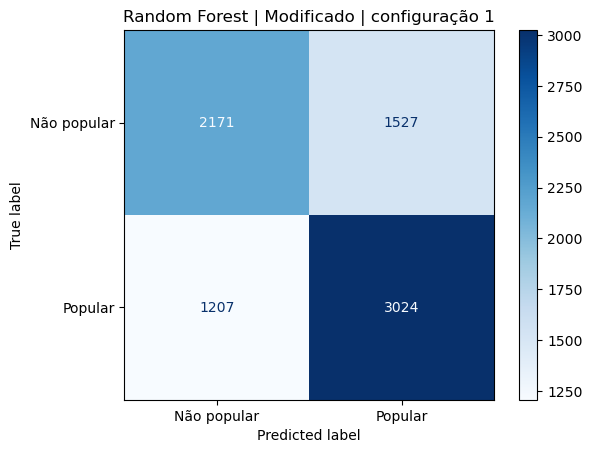


Modificado - Random Forest - configuração 2
              precision    recall  f1-score   support

           0       0.64      0.60      0.62      3698
           1       0.67      0.71      0.69      4231

    accuracy                           0.66      7929
   macro avg       0.66      0.65      0.65      7929
weighted avg       0.66      0.66      0.66      7929



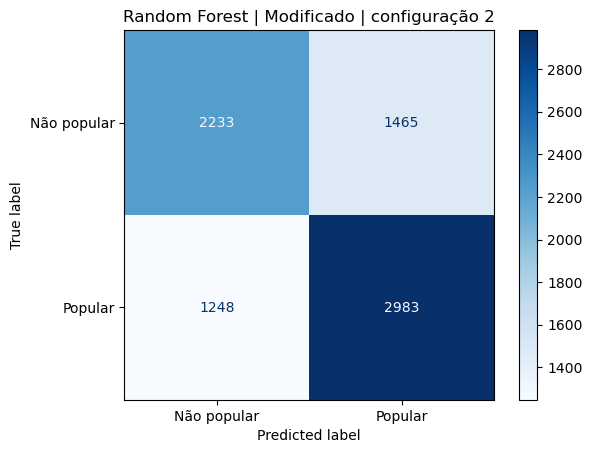

In [11]:
classification_datasets = {
    "Original": (X_train_original, X_test_original),
    "Modificado": (X_train_modified, X_test_modified),
}

random_forest_configs = [
    {
        "n_estimators": 100,
        "max_depth": None,
        "min_samples_leaf": 1,
        "class_weight": "balanced",
        "random_state": 42,
        "n_jobs": -1,
    },
    {
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_leaf": 2,
        "class_weight": "balanced",
        "random_state": 42,
        "n_jobs": -1,
    },
]

classification_results = []
classification_reports = {}
classification_models = {}


def evaluate_classifier(dataset_name, model_name, config_id, model, X_train, X_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    result_key = (dataset_name, model_name, config_id)

    classification_models[result_key] = model
    classification_reports[result_key] = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0,
    )
    classification_results.append(
        {
            "Dataset": dataset_name,
            "Modelo": model_name,
            "Configuração": config_id,
            "Acurácia": accuracy_score(y_test, predictions),
            "F1 macro": f1_score(y_test, predictions, average="macro"),
            "Precisão classe 1": classification_reports[result_key]["1"]["precision"],
            "Recall classe 1": classification_reports[result_key]["1"]["recall"],
        }
    )

    print(f"\n{dataset_name} - {model_name} - configuração {config_id}")
    print(classification_report(y_test, predictions, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Não popular", "Popular"],
        cmap="Blues",
        values_format="d",
    )
    plt.title(f"{model_name} | {dataset_name} | configuração {config_id}")
    plt.show()


for dataset_name, (X_train, X_test) in classification_datasets.items():
    for config_id, config in enumerate(random_forest_configs, start=1):
        evaluate_classifier(
            dataset_name,
            "Random Forest",
            config_id,
            RandomForestClassifier(**config),
            X_train,
            X_test,
        )



### Comparação dos resultados do Random Forest

Na classificação, a comparação deve priorizar o **F1 macro**, pois ele resume o desempenho nas duas classes e é menos enganoso quando as classes têm tamanhos diferentes. A acurácia, a precisão e o recall da classe popular também são apresentados.

In [12]:
classification_comparison = (
    pd.DataFrame(classification_results)
    .sort_values(["Modelo", "Dataset", "F1 macro"], ascending=[True, True, False])
    .reset_index(drop=True)
)
classification_comparison

,Dataset,Modelo,Configuração,Acurácia,F1 macro,Precisão classe 1,Recall classe 1
0,Modificado,Random Forest,2,0.657838,0.654749,0.670638,0.705034
1,Modificado,Random Forest,1,0.655190,0.651152,0.664469,0.714725
2,Original,Random Forest,2,0.663766,0.660211,0.673542,0.717797
3,Original,Random Forest,1,0.662000,0.657255,0.667458,0.730560


In [13]:
best_classification = (
    classification_comparison
    .sort_values("F1 macro", ascending=False)
    .groupby(["Modelo", "Dataset"], as_index=False)
    .first()
    .sort_values(["Modelo", "Dataset"])
)

print("Melhor configuração de classificação por modelo e conjunto:")
display(best_classification)


Melhor configuração de classificação por modelo e conjunto:


,Modelo,Dataset,Configuração,Acurácia,F1 macro,Precisão classe 1,Recall classe 1
0,Random Forest,Modificado,2,0.657838,0.654749,0.670638,0.705034
1,Random Forest,Original,2,0.663766,0.660211,0.673542,0.717797


## Agrupamento (K-Means)

Separamos os atributos de entrada das duas versões do dataset, excluindo `shares` e `url`.

A padronização dos dados e a execução do modelo serão realizadas posteriormente.

In [14]:
X_clustering_original = df_original.drop(columns=["url", "shares"])
X_clustering_modified = df_modified.drop(columns=["shares"])

print("Original:", X_clustering_original.shape)
print("Modified:", X_clustering_modified.shape)

Original: (39644, 59)
Modified: (39644, 50)


---
# Agrupamento com K-Means

## O que é o K-Means

O K-Means é um modelo **não supervisionado**: ele não usa a variável `shares` nem nenhum rótulo. Ele só olha os atributos das notícias e tenta dividi-las em `k` grupos de notícias parecidas entre si.

Como o algoritmo funciona:

1. Escolhe `k` pontos iniciais como **centróides** (o "centro" de cada grupo).
2. Atribui cada notícia ao centróide mais próximo (distância euclidiana).
3. Recalcula cada centróide como a média das notícias do grupo.
4. Repete os passos 2 e 3 até os centróides praticamente pararem de mudar (ou até atingir o limite de iterações).

O que o algoritmo minimiza é a **inércia**: a soma das distâncias ao quadrado de cada ponto até o centróide do seu grupo. Inércia sempre cai quando `k` aumenta, então ela sozinha não serve para escolher `k`.

**Por que padronizar?** Como o K-Means usa distância, um atributo com valores grandes (ex.: `kw_max_max`, na casa das centenas de milhares) dominaria atributos pequenos (ex.: `global_subjectivity`, entre 0 e 1). O `StandardScaler` deixa todos os atributos com média 0 e desvio padrão 1.

**Como avaliar: Índice de Silhueta.** Para cada ponto, compara a distância média aos pontos do próprio grupo (`a`) com a distância média ao grupo vizinho mais próximo (`b`): `s = (b − a) / max(a, b)`. A média vai de −1 a 1:

| Silhueta | Interpretação |
|---|---|
| próximo de 1 | grupos compactos e bem separados |
| próximo de 0 | grupos sobrepostos, fronteiras pouco definidas |
| negativo | muitos pontos estão no grupo errado |

Calcular a silhueta exata em ~39 mil notícias exige comparar todos os pares de pontos, o que é lento. Por isso usamos uma **amostra fixa de 10.000 notícias** (`sample_size=10000`, `random_state=42`), a mesma em todos os testes.

## Parâmetros do `KMeans` no scikit-learn

| Parâmetro | Padrão | O que faz |
|---|---|---|
| `n_clusters` | 8 | Número de grupos `k`. É o parâmetro mais importante. |
| `init` | `"k-means++"` | Como escolher os centróides iniciais. `"k-means++"` espalha os centróides iniciais longe uns dos outros (converge melhor); `"random"` sorteia pontos aleatórios. Também aceita uma matriz com centróides definidos à mão. |
| `n_init` | `"auto"` | Quantas vezes o algoritmo roda com inicializações diferentes. O resultado final é a rodada de menor inércia. Mais rodadas = resultado mais estável, porém mais lento. |
| `max_iter` | 300 | Número máximo de iterações (passos 2–3) em cada rodada. Se for muito baixo, o algoritmo para antes de convergir. |
| `tol` | 1e-4 | Tolerância de convergência: se os centróides se moverem menos que isso entre duas iterações, o algoritmo para. Valor maior = para mais cedo. |
| `algorithm` | `"lloyd"` | Variante do algoritmo. `"lloyd"` é o clássico; `"elkan"` usa a desigualdade triangular para evitar cálculos de distância desnecessários. Ambos dão o mesmo resultado, muda só a velocidade. |
| `random_state` | None | Semente aleatória. Fixamos em 42 para os resultados serem reproduzíveis. |
| `verbose` | 0 | Se > 0, imprime o progresso do treino. |
| `copy_x` | True | Se True, não modifica os dados de entrada ao centralizá-los internamente. |

Atributos úteis do modelo treinado: `labels_` (grupo de cada notícia), `cluster_centers_` (centróides), `inertia_` (inércia) e `n_iter_` (iterações realizadas).

A função abaixo treina um K-Means com qualquer combinação de parâmetros e devolve as métricas. Ela é usada em todos os testes e pode ser chamada durante a apresentação para testar outros valores.

In [15]:
AMOSTRA_SILHUETA = 10_000  # nº de notícias usadas para estimar a silhueta


def rodar_kmeans(X_escalado, **parametros):
    # Treina um K-Means com os parâmetros informados e devolve modelo + métricas.
    config = {"random_state": 42, **parametros}
    inicio = time.perf_counter()
    modelo = KMeans(**config).fit(X_escalado)
    duracao = time.perf_counter() - inicio

    silhueta = silhouette_score(
        X_escalado, modelo.labels_,
        sample_size=AMOSTRA_SILHUETA, random_state=42,
    )
    tamanhos = np.bincount(modelo.labels_)
    return {
        "modelo": modelo,
        "silhueta": silhueta,
        "inercia": modelo.inertia_,
        "iteracoes": modelo.n_iter_,
        "tempo_s": duracao,
        "menor_grupo": tamanhos.min(),
        "maior_grupo": tamanhos.max(),
    }

### Passo 1 — Padronização e primeiro teste

Padronizamos os dois conjuntos (`X_clustering_original` e `X_clustering_modified`, preparados acima) e rodamos o K-Means com `k` de 2 a 10 para ter uma primeira visão. Além da silhueta, olhamos o **tamanho do menor grupo**, que ajuda a perceber se algum grupo é só um punhado de pontos estranhos.

In [16]:
conjuntos_brutos = {
    "Original": StandardScaler().fit_transform(X_clustering_original),
    "Modificado": StandardScaler().fit_transform(X_clustering_modified),
}

linhas = []
for nome, X_esc in conjuntos_brutos.items():
    for k in range(2, 11):
        r = rodar_kmeans(X_esc, n_clusters=k, n_init=10)
        linhas.append({"Conjunto": nome, "k": k,
                       "Silhueta": round(r["silhueta"], 4),
                       "Menor grupo": r["menor_grupo"]})

diagnostico = pd.DataFrame(linhas)
diagnostico.pivot(index="k", columns="Conjunto", values=["Silhueta", "Menor grupo"])

Silhueta          Menor grupo         
Conjunto Modificado Original  Modificado Original
k                                                
2            0.3245   0.3026      1186.0   1187.0
3            0.0773   0.0707      1186.0   1184.0
4            0.0817   0.0543      1185.0   1184.0
5            0.0995   0.0763      1185.0      1.0
6            0.0995   0.0851         1.0      1.0
7            0.0984   0.0820         1.0      1.0
8            0.1021   0.0838         1.0      1.0
9            0.1246   0.0914         1.0      1.0
10           0.1189   0.0893         1.0      1.0

**O que a tabela mostra?** Com `k = 2` a silhueta parece ótima (0,30 no original e 0,32 no modificado), muito acima de qualquer outro `k`. Mas o menor grupo tem só ~1.186 notícias, e a partir de `k = 5` ou `6` aparece um grupo com **uma única notícia**.

Isso indica que o K-Means está isolando pontos estranhos, e não encontrando tipos de notícia. **Silhueta alta não garante agrupamento útil**: um grupo pequeno e muito diferente do resto fica "bem separado" e puxa a média para cima. A célula abaixo mostra quem são esses pontos.

In [17]:
modelo_k2 = rodar_kmeans(conjuntos_brutos["Modificado"], n_clusters=2, n_init=10)["modelo"]
grupo_pequeno = np.argmin(np.bincount(modelo_k2.labels_))
no_grupo_pequeno = modelo_k2.labels_ == grupo_pequeno

print("Notícias no grupo pequeno do k=2:", no_grupo_pequeno.sum())
print("Delas, quantas têm n_tokens_content = 0 (texto vazio):",
      (X_clustering_modified.loc[no_grupo_pequeno, "n_tokens_content"] == 0).sum())
print("Total de notícias com texto vazio no dataset:",
      (X_clustering_modified["n_tokens_content"] == 0).sum())

print("\nRegistro com taxa de palavras únicas impossível (deveria estar entre 0 e 1):")
display(df_original.loc[df_original["n_unique_tokens"] > 1,
        ["url", "n_tokens_content", "n_unique_tokens", "n_non_stop_words", "n_non_stop_unique_tokens"]])

Notícias no grupo pequeno do k=2: 1186
Delas, quantas têm n_tokens_content = 0 (texto vazio): 1181
Total de notícias com texto vazio no dataset: 1181

Registro com taxa de palavras únicas impossível (deveria estar entre 0 e 1):


,url,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens
31037,http://mashable.com/2014/08/18/ukraine-civilia...,1570.0,701.0,1042.0,650.0


### Passo 2 — Tratamento técnico dos dados

Para que o K-Means agrupe as notícias pelo seu conteúdo, e não por erros de coleta, removemos **apenas para o agrupamento**:

- notícias com `n_tokens_content = 0` (sem texto: todas as métricas de texto ficam zeradas);
- o registro com `n_unique_tokens > 1` (valor impossível para uma taxa).

A mesma máscara é aplicada aos dois conjuntos, então original e modificado continuam com exatamente as mesmas notícias. O arquivo CSV e as variáveis usadas na classificação não são alterados.

In [18]:
mascara_validas = (
    (df_original["n_tokens_content"] > 0)
    & (df_original["n_unique_tokens"] <= 1)
)

X_km_original = X_clustering_original.loc[mascara_validas]
X_km_modified = X_clustering_modified.loc[mascara_validas]

conjuntos = {
    "Original": StandardScaler().fit_transform(X_km_original),
    "Modificado": StandardScaler().fit_transform(X_km_modified),
}

print("Notícias removidas:", (~mascara_validas).sum())
for nome, X_esc in conjuntos.items():
    print(f"{nome}: {X_esc.shape[0]} notícias x {X_esc.shape[1]} atributos")

Notícias removidas: 1182
Original: 38462 notícias x 59 atributos
Modificado: 38462 notícias x 50 atributos


### Passo 3 — Escolha do número de grupos (`n_clusters`)

Testamos `k` de 2 a 10 nos dados tratados, com os demais parâmetros no padrão (`init="k-means++"`, `n_init=10`, `max_iter=300`). Dois critérios:

- **Método do cotovelo:** procurar o `k` a partir do qual a inércia passa a cair pouco.
- **Silhueta:** quanto maior, melhor a separação.

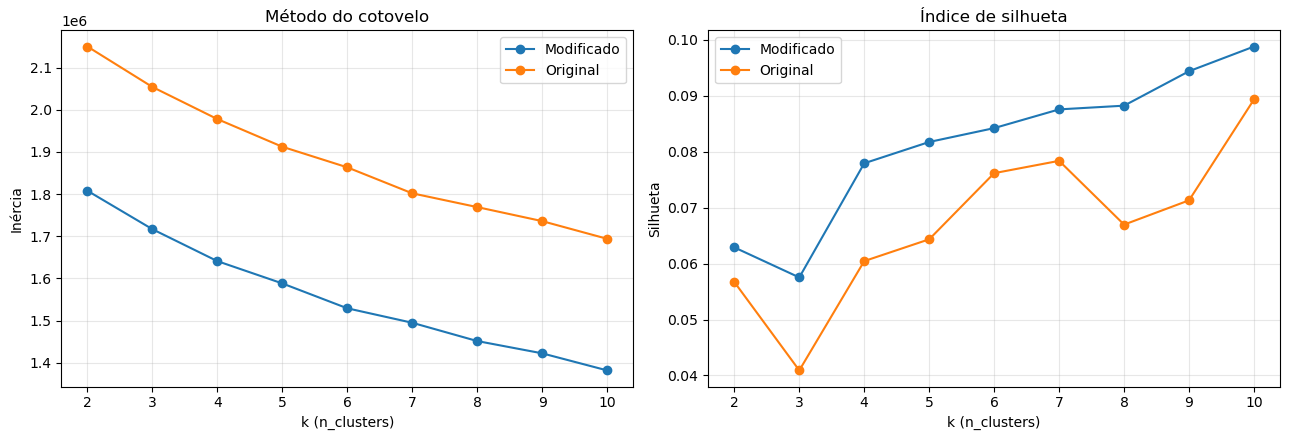

,Conjunto,k,Inércia,Silhueta,Menor grupo,Maior grupo
0,Original,2,2.150199e+06,0.0567,18013,20449
1,Original,3,2.054303e+06,0.0409,8343,17771
2,Original,4,1.978129e+06,0.0604,7854,12946
3,Original,5,1.912473e+06,0.0643,4107,11846
4,Original,6,1.863626e+06,0.0762,163,9054
5,Original,7,1.802009e+06,0.0784,162,7659
6,Original,8,1.769334e+06,0.0670,163,8683
7,Original,9,1.736061e+06,0.0713,25,7198
8,Original,10,1.694122e+06,0.0893,160,7342
9,Modificado,2,1.808080e+06,0.0629,16809,21653


In [19]:
linhas = []
for nome, X_esc in conjuntos.items():
    for k in range(2, 11):
        r = rodar_kmeans(X_esc, n_clusters=k, n_init=10)
        linhas.append({"Conjunto": nome, "k": k,
                       "Inércia": r["inercia"],
                       "Silhueta": r["silhueta"],
                       "Menor grupo": r["menor_grupo"],
                       "Maior grupo": r["maior_grupo"]})
varredura_k = pd.DataFrame(linhas)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, dados in varredura_k.groupby("Conjunto"):
    eixos[0].plot(dados["k"], dados["Inércia"], marker="o", label=nome)
    eixos[1].plot(dados["k"], dados["Silhueta"], marker="o", label=nome)
eixos[0].set(title="Método do cotovelo", xlabel="k (n_clusters)", ylabel="Inércia")
eixos[1].set(title="Índice de silhueta", xlabel="k (n_clusters)", ylabel="Silhueta")
for eixo in eixos:
    eixo.legend(); eixo.grid(alpha=0.3)
plt.tight_layout(); plt.show()

varredura_k.round(4)

**Análise:**

- **Cotovelo:** a inércia cai de forma suave, sem uma "dobra" clara. Isso já sugere que as notícias não formam grupos naturais bem definidos.
- **Silhueta:** fica baixa em todos os valores de `k` (entre 0,04 e 0,10), ou seja, os grupos se sobrepõem. É esperado: as notícias variam de forma contínua (tamanho, sentimento, canal...), sem fronteiras nítidas.
- A silhueta cresce devagar com `k` e é máxima em `k = 10`, mas a partir de `k = 6` surge um grupo minúsculo (130 notícias no modificado, 163 no original). Esses grupos pequenos reúnem casos extremos, não um tipo de notícia.
- **Escolhemos `k = 5`:** é o maior `k` sem grupos minúsculos, os grupos têm tamanhos equilibrados (de 5.922 a 9.032 notícias no modificado) e, como veremos no Passo 5, cada grupo tem uma interpretação clara.
- Em **todos** os valores de `k`, o conjunto modificado tem silhueta maior que o original.

In [20]:
K_ESCOLHIDO = 5

### Passo 4 — Testes com os demais parâmetros

Com `k` fixo, variamos um parâmetro de cada vez a partir de uma configuração base (`init="k-means++"`, `n_init=10`, `max_iter=300`, `tol=1e-4`, `algorithm="lloyd"`). Assim dá para ver o efeito isolado de cada um. Para cada teste registramos silhueta, inércia, iterações e tempo.

In [21]:
base = {"n_clusters": K_ESCOLHIDO, "init": "k-means++", "n_init": 10,
        "max_iter": 300, "tol": 1e-4, "algorithm": "lloyd"}

testes = {
    "Base (k-means++, n_init=10)":   {},
    "init='random'":                 {"init": "random"},
    "n_init=1":                      {"n_init": 1},
    "init='random', n_init=1":       {"init": "random", "n_init": 1},
    "n_init=30":                     {"n_init": 30},
    "max_iter=3":                    {"max_iter": 3},
    "max_iter=20":                   {"max_iter": 20},
    "tol=1e-1":                      {"tol": 1e-1},
    "algorithm='elkan'":             {"algorithm": "elkan"},
}

linhas = []
for nome, X_esc in conjuntos.items():
    for descricao, mudanca in testes.items():
        r = rodar_kmeans(X_esc, **{**base, **mudanca})
        linhas.append({"Conjunto": nome, "Teste": descricao,
                       "Silhueta": r["silhueta"], "Inércia": r["inercia"],
                       "Iterações": r["iteracoes"], "Tempo (s)": r["tempo_s"]})

testes_parametros = pd.DataFrame(linhas)
testes_parametros.pivot(index="Teste", columns="Conjunto",
                        values=["Silhueta", "Inércia", "Iterações", "Tempo (s)"]
                        ).loc[list(testes)].round(4)

Silhueta                Inércia                \
Conjunto                    Modificado Original    Modificado      Original   
Teste                                                                         
Base (k-means++, n_init=10)     0.0817   0.0643  1.588285e+06  1.912473e+06   
init='random'                   0.0819   0.0643  1.588281e+06  1.912473e+06   
n_init=1                        0.0777   0.0658  1.593817e+06  1.915778e+06   
init='random', n_init=1         0.0639   0.0487  1.604752e+06  1.941988e+06   
n_init=30                       0.0819   0.0643  1.588281e+06  1.912472e+06   
max_iter=3                      0.0827   0.0546  1.590460e+06  1.930466e+06   
max_iter=20                     0.0816   0.0643  1.588287e+06  1.912479e+06   
tol=1e-1                        0.0801   0.0618  1.588977e+06  1.921615e+06   
algorithm='elkan'               0.0817   0.0643  1.588285e+06  1.912473e+06   

                             Iterações           Tempo (s)           
Conjunto                    Modificado Original Modificado Original  
Teste                                                                
Base (k-means++, n_init=10)       22.0     22.0     0.3448   0.4179  
init='random'                    102.0     32.0     0.3469   0.3017  
n_init=1                          18.0     31.0     0.0285   0.0434  
init='random', n_init=1           45.0     63.0     0.0437   0.0639  
n_init=30                         47.0     42.0     0.9353   1.0443  
max_iter=3                         3.0      3.0     0.0864   0.0950  
max_iter=20                       20.0     20.0     0.2079   0.2294  
tol=1e-1                          12.0     11.0     0.1313   0.1380  
algorithm='elkan'                 22.0     22.0     0.3818   0.3583

**Análise dos parâmetros:**

- **`init`:** com `n_init=10`, trocar `k-means++` por `random` dá praticamente o mesmo resultado, mas o `random` precisou de bem mais iterações no modificado (102 contra 22): partindo de centróides ruins, demora mais para convergir.
- **`n_init`:** com só 1 inicialização o resultado piora, e o pior caso é `random` + `n_init=1` (silhueta 0,064 no modificado e 0,049 no original, com a maior inércia). Rodar várias vezes protege contra um início ruim. Já `n_init=30` não melhora nada em relação a 10 e leva cerca de 3 vezes mais tempo.
- **`max_iter`:** com 3 iterações o algoritmo para antes de convergir e a inércia fica maior. Com 20 o resultado já é quase igual ao da base, porque a base converge em 22 iterações. (No modificado, `max_iter=3` deu silhueta um pouco maior mesmo com inércia pior: a silhueta e a inércia medem coisas diferentes, e o K-Means otimiza a inércia.)
- **`tol`:** com `tol=0.1` o critério de parada é mais frouxo, o algoritmo para em 11–12 iterações e o resultado fica um pouco pior.
- **`algorithm`:** `elkan` e `lloyd` chegam exatamente ao mesmo resultado; só muda a forma de calcular. Neste conjunto o tempo ficou parecido.

Conclusão: o parâmetro que mais muda o resultado é `n_clusters`. Os outros afetam principalmente a estabilidade (`init`, `n_init`) e o custo (`max_iter`, `tol`, `algorithm`). A configuração base (`k-means++`, `n_init=10`, `max_iter=300`) é uma boa escolha.

### Passo 5 — Modelo final e análise dos grupos

Treinamos o modelo final em cada conjunto com a configuração base e `k = K_ESCOLHIDO`.

**Gráfico de silhueta:** cada barra horizontal é uma notícia (amostra de 5.000), ordenada dentro do seu grupo. Barras à direita do zero estão bem encaixadas no grupo; barras à esquerda (negativas) estariam melhor em outro grupo. A linha tracejada é a silhueta média.

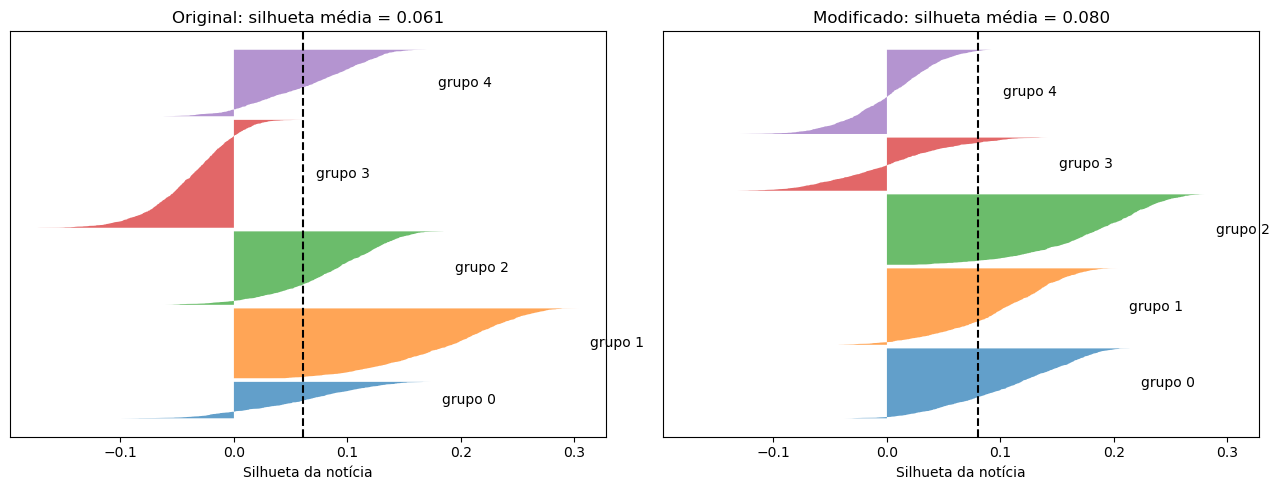

Original: tamanhos dos grupos = [4107, 7735, 7786, 11846, 6988] | notícias com silhueta negativa = 30.9%
Modificado: tamanhos dos grupos = [7223, 8384, 7901, 5922, 9032] | notícias com silhueta negativa = 18.8%


In [22]:
modelos_finais = {nome: rodar_kmeans(X_esc, **base) for nome, X_esc in conjuntos.items()}

rng = np.random.default_rng(42)
pct_negativos = {}
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for eixo, (nome, X_esc) in zip(eixos, conjuntos.items()):
    rotulos = modelos_finais[nome]["modelo"].labels_
    idx = rng.choice(len(X_esc), 5000, replace=False)
    valores = silhouette_samples(X_esc[idx], rotulos[idx])

    y = 0
    for g in range(K_ESCOLHIDO):
        v = np.sort(valores[rotulos[idx] == g])
        eixo.fill_betweenx(np.arange(y, y + len(v)), 0, v, alpha=0.7)
        eixo.text(v.max() + 0.01, y + len(v) / 2, f"grupo {g}", va="center")
        y += len(v) + 50
    eixo.axvline(valores.mean(), color="black", linestyle="--")
    pct_negativos[nome] = (valores < 0).mean()
    eixo.set(title=f"{nome}: silhueta média = {valores.mean():.3f}",
             xlabel="Silhueta da notícia", yticks=[])
plt.tight_layout(); plt.show()

for nome, r in modelos_finais.items():
    print(f"{nome}: tamanhos dos grupos = {np.bincount(r['modelo'].labels_).tolist()} | "
          f"notícias com silhueta negativa = {pct_negativos[nome]:.1%}")

**Visualização em 2D (PCA).** Os dados têm dezenas de dimensões, então usamos PCA apenas para *desenhar* os grupos em duas dimensões. O K-Means foi treinado em todas as dimensões; o gráfico é só uma projeção e perde parte da informação.

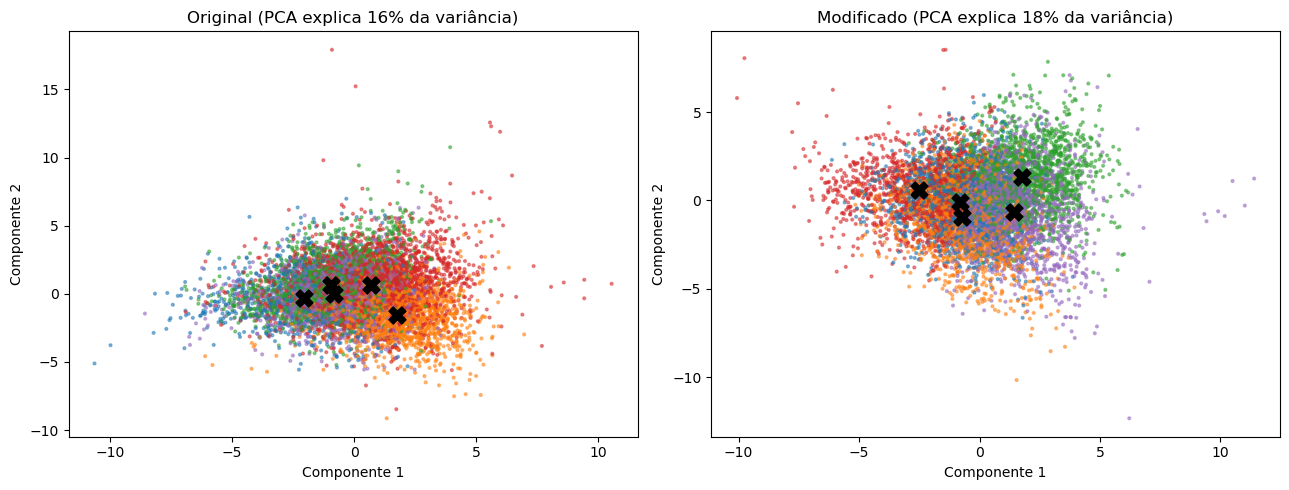

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for eixo, (nome, X_esc) in zip(eixos, conjuntos.items()):
    pca = PCA(n_components=2, random_state=42)
    pontos = pca.fit_transform(X_esc)
    rotulos = modelos_finais[nome]["modelo"].labels_
    centros = pca.transform(modelos_finais[nome]["modelo"].cluster_centers_)

    idx = rng.choice(len(pontos), 8000, replace=False)
    eixo.scatter(pontos[idx, 0], pontos[idx, 1], c=rotulos[idx], cmap="tab10",
                 s=4, alpha=0.5, vmin=0, vmax=9)
    eixo.scatter(centros[:, 0], centros[:, 1], c="black", marker="X", s=150)
    variancia = pca.explained_variance_ratio_.sum()
    eixo.set(title=f"{nome} (PCA explica {variancia:.0%} da variância)",
             xlabel="Componente 1", ylabel="Componente 2")
plt.tight_layout(); plt.show()

**O que caracteriza cada grupo?** Para o conjunto modificado, mostramos a média de alguns atributos por grupo. A variável `shares` **não foi usada no treino**, mas podemos usá-la depois para ver se algum grupo concentra mais notícias populares (≥ 1.400 compartilhamentos).

In [24]:
canais = ["data_channel_is_lifestyle", "data_channel_is_entertainment", "data_channel_is_bus",
          "data_channel_is_socmed", "data_channel_is_tech", "data_channel_is_world"]

def canal_predominante(dados):
    medias = dados[canais].mean()
    sem_canal = 1 - medias.sum()
    if sem_canal > medias.max():
        return "sem canal / outros"
    return medias.idxmax().replace("data_channel_is_", "")

perfil = X_km_modified.copy()
perfil["grupo"] = modelos_finais["Modificado"]["modelo"].labels_
perfil["popular"] = y_classification.loc[mascara_validas]
perfil["shares"] = df_original.loc[mascara_validas, "shares"]

resumo_grupos = perfil.groupby("grupo").agg(
    noticias=("popular", "size"),
    canal_predominante=("grupo", lambda s: canal_predominante(perfil.loc[s.index])),
    fim_de_semana=("is_weekend", "mean"),
    palavras_no_texto=("n_tokens_content", "mean"),
    imagens=("num_imgs", "mean"),
    subjetividade=("global_subjectivity", "mean"),
    polaridade=("global_sentiment_polarity", "mean"),
    shares_mediana=("shares", "median"),
    pct_populares=("popular", "mean"),
)
print(f"Notícias populares no conjunto todo: {perfil['popular'].mean():.1%}")
resumo_grupos.round(3)

Notícias populares no conjunto todo: 53.2%


,noticias,canal_predominante,fim_de_semana,palavras_no_texto,imagens,subjetividade,polaridade,shares_mediana,pct_populares
grupo,,,,,,,,,
0,7223,bus,0.094,566.454,2.011,0.436,0.134,1600.0,0.583
1,8384,tech,0.138,618.574,4.640,0.459,0.146,1700.0,0.642
2,7901,world,0.127,628.027,2.549,0.410,0.068,1100.0,0.375
3,5922,sem canal / outros,0.135,213.627,2.847,0.493,0.206,1400.0,0.534
4,9032,entertainment,0.154,681.985,9.415,0.489,0.087,1400.0,0.525


E no conjunto **original**? Repetimos a análise incluindo as colunas que foram removidas na modificação (`timedelta` = dias entre a publicação e a coleta; `kw_*` = estatísticas de compartilhamento das palavras-chave).

In [25]:
perfil_original = X_km_original.copy()
perfil_original["grupo"] = modelos_finais["Original"]["modelo"].labels_
perfil_original["popular"] = y_classification.loc[mascara_validas]

perfil_original.groupby("grupo").agg(
    noticias=("popular", "size"),
    canal_predominante=("grupo", lambda s: canal_predominante(perfil_original.loc[s.index])),
    dias_desde_publicacao=("timedelta", "mean"),
    kw_min_min=("kw_min_min", "mean"),
    kw_max_max=("kw_max_max", "mean"),
    kw_avg_avg=("kw_avg_avg", "mean"),
    pct_populares=("popular", "mean"),
).round(2)

,noticias,canal_predominante,dias_desde_publicacao,kw_min_min,kw_max_max,kw_avg_avg,pct_populares
grupo,,,,,,,
0,4107,tech,692.67,213.17,197489.29,2325.09,0.59
1,7735,world,261.03,3.54,824164.71,2504.11,0.37
2,7786,tech,358.91,4.40,807875.40,2872.76,0.62
3,11846,entertainment,318.23,4.53,818775.70,3957.36,0.53
4,6988,bus,348.21,5.22,813291.59,3033.70,0.58


**Interpretação dos grupos:**

- **Modificado:** os 5 grupos correspondem quase exatamente aos **canais** das notícias: negócios, tecnologia, mundo, entretenimento e um grupo de notícias sem canal definido, que são bem mais curtas (~214 palavras contra 570–680 dos outros), mais subjetivas e mais positivas. O grupo de entretenimento se destaca por ter muito mais imagens (9,4 em média).
- Mesmo sem ver `shares`, os grupos têm popularidade diferente: no grupo **mundo** só 37,5% das notícias são populares (a mediana é 1.100 compartilhamentos), enquanto no grupo **tecnologia** são 64,2% (a média geral é 53,2%).
- **Original:** quatro grupos também seguem os canais, mas o grupo 0 junta notícias de vários canais misturados. O que elas têm em comum é serem as **mais antigas** do conjunto (~693 dias desde a publicação, contra ~260–360 nos outros), com valores de `kw_min_min` e `kw_max_max` muito diferentes. Ou seja, no original um dos grupos é definido por **quando a notícia foi coletada**, e não pelo seu conteúdo. São exatamente as colunas que a modificação remove.
- No gráfico de silhueta do original, o grupo 3 (entretenimento) tem a maioria das notícias com silhueta negativa: elas ficam quase tão perto de outro grupo quanto do próprio.

### Passo 6 — Comparação: conjunto original × conjunto modificado

In [26]:
melhor_k = varredura_k.loc[varredura_k.groupby("Conjunto")["Silhueta"].idxmax(), ["Conjunto", "k", "Silhueta"]]
melhor_k = melhor_k.set_index("Conjunto")

comparacao_kmeans = pd.DataFrame({
    nome: {
        "Nº de atributos": conjuntos[nome].shape[1],
        f"Silhueta (k={K_ESCOLHIDO})": round(r["silhueta"], 4),
        f"Inércia (k={K_ESCOLHIDO})": round(r["inercia"], 0),
        "Inércia por atributo": round(r["inercia"] / conjuntos[nome].shape[1], 0),
        "Iterações até convergir": r["iteracoes"],
        "% notícias com silhueta negativa": f"{pct_negativos[nome]:.1%}",
        "Melhor k pela silhueta (2–10)": int(melhor_k.loc[nome, "k"]),
        "Silhueta no melhor k": round(melhor_k.loc[nome, "Silhueta"], 4),
        "Silhueta k=2 sem tratamento": diagnostico.query("Conjunto == @nome and k == 2")["Silhueta"].item(),
    }
    for nome, r in modelos_finais.items()
}).astype(object)
comparacao_kmeans

,Original,Modificado
Nº de atributos,59,50
Silhueta (k=5),0.0643,0.0817
Inércia (k=5),1912473.0,1588285.0
Inércia por atributo,32415.0,31766.0
Iterações até convergir,22,22
% notícias com silhueta negativa,30.9%,18.8%
Melhor k pela silhueta (2–10),10,10
Silhueta no melhor k,0.0893,0.0988
Silhueta k=2 sem tratamento,0.3026,0.3245


## Conclusão do K-Means

**Original × modificado:**

- O conjunto **modificado gerou grupos melhores** em todas as medidas: silhueta de 0,082 contra 0,064 com `k = 5` (cerca de 27% maior), menos notícias mal agrupadas (18,8% com silhueta negativa contra 30,9%) e silhueta maior em todos os valores de `k` testados.
- A modificação removeu 9 atributos (`timedelta` e as estatísticas `kw_*`). Eles não descrevem o conteúdo da notícia: medem a idade da notícia e o histórico de compartilhamento das palavras-chave. Com eles, o K-Means criou um grupo de "notícias antigas". Sem eles, os grupos passam a refletir o tipo de conteúdo (canal, tamanho, sentimento).
- A inércia total do original é maior, mas isso acontece só porque ele tem mais atributos. Dividindo pelo número de atributos, as duas ficam parecidas, por isso a comparação é feita pela silhueta.

**Limitações:**

- A silhueta é baixa nos dois conjuntos (abaixo de 0,1). Os grupos existem e fazem sentido, mas se sobrepõem bastante: as notícias não se dividem em grupos naturalmente separados.
- O K-Means supõe grupos de formato aproximadamente esférico e é sensível a outliers, como vimos no diagnóstico: sem o tratamento, `k = 2` dava silhueta de 0,30–0,32 só por isolar as notícias sem texto. Esse resultado parece bom, mas não representa um agrupamento útil.
- A silhueta foi estimada em uma amostra de 10.000 notícias por causa do custo computacional (os valores do gráfico de silhueta, com 5.000 notícias, são um pouco diferentes por isso).

### Espaço para testes ao vivo

Altere os valores abaixo e rode a célula para testar outras combinações de parâmetros.

In [27]:
resultado = rodar_kmeans(
    conjuntos["Modificado"],   # ou conjuntos["Original"]
    n_clusters=4,
    init="random",
    n_init=5,
    max_iter=100,
    tol=1e-4,
    algorithm="lloyd",
)
{chave: valor for chave, valor in resultado.items() if chave != "modelo"}

{'silhueta': 0.07792768664478872,
 'inercia': 1641140.8115604385,
 'iteracoes': 48,
 'tempo_s': 0.15761408300022595,
 'menor_grupo': 8107,
 'maior_grupo': 13069}